# Part A (Sahana K S, PES2UG24CS425)
## Data pipeline and from-scratch models: Linear SVM, Softmax, Two-layer Net
UE24CS352A Mini-Project, Section G, Team 7, Problem 75: Distracted Driver Detection

## Step 1. Connect Google Drive and unpack the code
A pop-up asks for Drive permission: click **Connect to Google Drive** and allow.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

TEAM = '/content/drive/MyDrive/DDD_Team7'          # the shared folder
import os
assert os.path.exists(TEAM + '/distracted-driver-detection.zip'), 'Put distracted-driver-detection.zip inside MyDrive/DDD_Team7 first'
!rm -rf /content/distracted-driver-detection
!unzip -q -o "$TEAM/distracted-driver-detection.zip" -d /content
%cd /content/distracted-driver-detection
%env DDD_OUT=/content/drive/MyDrive/DDD_Team7/outputs
!pip -q install -r requirements.txt
print('Code ready. All results will be saved in MyDrive/DDD_Team7/outputs')

Mounted at /content/drive
/content/distracted-driver-detection
env: DDD_OUT=/content/drive/MyDrive/DDD_Team7/outputs
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 36.6 MB/s eta 0:00:00
Code ready. All results will be saved in MyDrive/DDD_Team7/outputs


## Step 2. Download the dataset from Kaggle (about 5 minutes)
Needs your Kaggle token saved in Colab Secrets (key icon on the left) under the name `KAGGLE_API_TOKEN`, with Notebook access switched on.

In [2]:
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
!pip -q install -U kaggle
!kaggle competitions download -c state-farm-distracted-driver-detection -p /content
!unzip -q -o /content/state-farm-distracted-driver-detection.zip "imgs/train/*" "driver_imgs_list.csv" -d /content/data
!rm -f /content/state-farm-distracted-driver-detection.zip
!ls /content/data /content/data/imgs/train

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.3 MB/s eta 0:00:00
100% 4.00G/4.00G [00:43<00:00, 99.3MB/s]

/content/data:
driver_imgs_list.csv  imgs

/content/data/imgs/train:
c0  c1	c2  c3	c4  c5	c6  c7	c8  c9


## Step 3. Resize all images to 64x64 and cache them (about 5 minutes)

Reading 22424 images and resizing to 64x64 (takes a few minutes) ...
Cached to /content/distracted-driver-detection/data/cache/statefarm_64.npz
X (22424, 64, 64, 3) y (22424,) distinct drivers 26
random  split: train 17939  val 4485  drivers in both sets: 26
driver  split: train 17446  val 4978  drivers in both sets: 0
Saved results/figures/samples.png and class_distribution.png


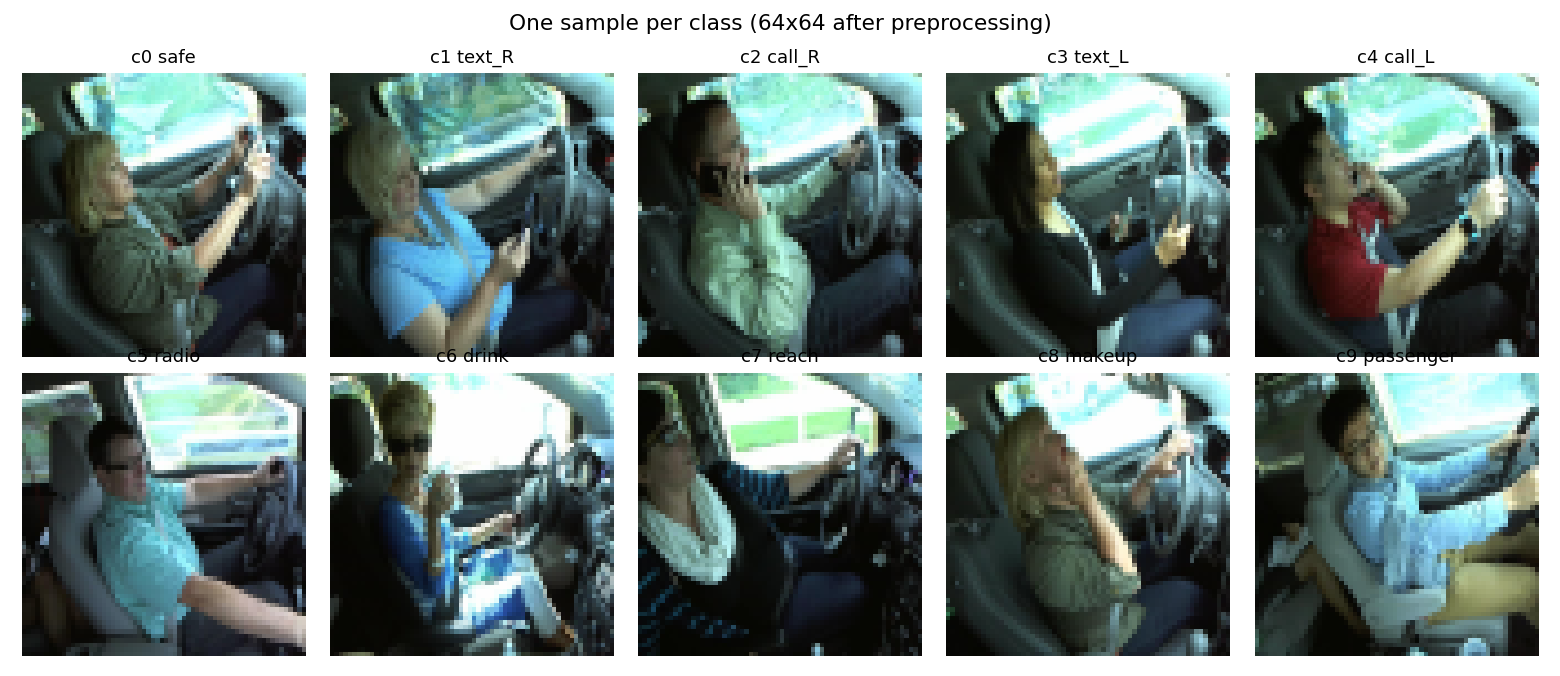

In [3]:
!python -m src.data
from IPython.display import Image, display
display(Image('/content/drive/MyDrive/DDD_Team7/outputs/results/figures/samples.png'))

## Step 4. Check that the hand-written gradients are correct
Expect an error around 1e-10.

In [4]:
!python -m src.models_scratch

max |numerical - analytic| gradient error: 3.8564471060986705e-11


## Step 5. Train Linear SVM, Softmax and the Two-layer Net on both splits (about 20 to 30 minutes)
Each model: grid search, refit on the training set, score on the validation set.

In [5]:
!python -m src.train_scratch

Loaded (22424, 64, 64, 3)

=== linear_svm  |  split = random ===
  lr=3e-06 reg=1e-02  tune acc 0.6637
  lr=3e-06 reg=1e-01  tune acc 0.6637
  lr=3e-06 reg=1e+00  tune acc 0.6633
  lr=1e-05 reg=1e-02  tune acc 0.8521
  lr=1e-05 reg=1e-01  tune acc 0.8521
  lr=1e-05 reg=1e+00  tune acc 0.8502
  lr=3e-05 reg=1e-02  tune acc 0.9357
  lr=3e-05 reg=1e-01  tune acc 0.9361
  lr=3e-05 reg=1e+00  tune acc 0.9357
  lr=1e-04 reg=1e-02  tune acc 0.9777
  lr=1e-04 reg=1e-01  tune acc 0.9781
  lr=1e-04 reg=1e+00  tune acc 0.9762
  best hyperparameters: {'lr': 0.0001, 'reg': 0.1}
    iter     0/2000  loss 9.1262
    iter   250/2000  loss 0.9771
    iter   500/2000  loss 0.5732
    iter   750/2000  loss 0.4042
    iter  1000/2000  loss 0.3370
    iter  1250/2000  loss 0.3412
    iter  1500/2000  loss 0.2337
    iter  1750/2000  loss 0.2201
  >> linear_svm [random]  train 0.9836  val 0.9770  macroF1 0.9765

=== softmax  |  split = random ===
  lr=3e-06 reg=1e-02  tune acc 0.3404
  lr=3e-06 reg=1e-01  t

## Step 6. Look at the results

linear_svm      driver  train 92.1%  val 36.9%  best {'lr': 1e-05, 'reg': 0.01}
linear_svm      random  train 98.4%  val 97.7%  best {'lr': 0.0001, 'reg': 0.1}
softmax         driver  train 73.2%  val 30.5%  best {'lr': 3e-05, 'reg': 1.0}
softmax         random  train 85.2%  val 84.0%  best {'lr': 0.0001, 'reg': 0.01}
two_layer_net   driver  train 98.4%  val 35.3%  best {'lr': 0.0001, 'reg': 0.0001}
two_layer_net   random  train 100.0%  val 99.4%  best {'lr': 0.001, 'reg': 0.0001}


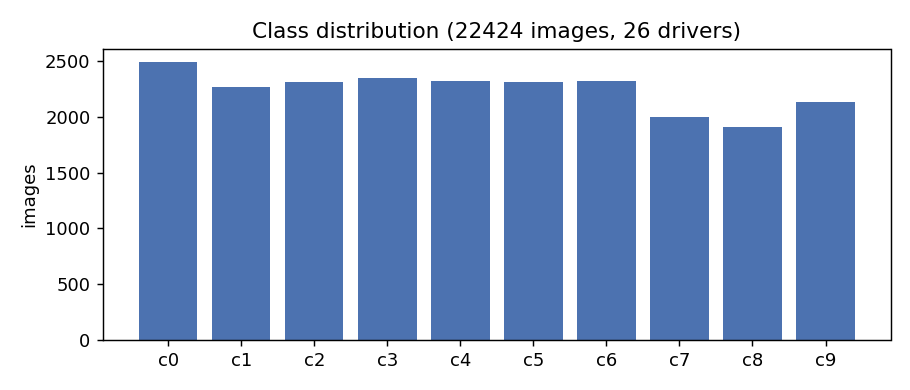

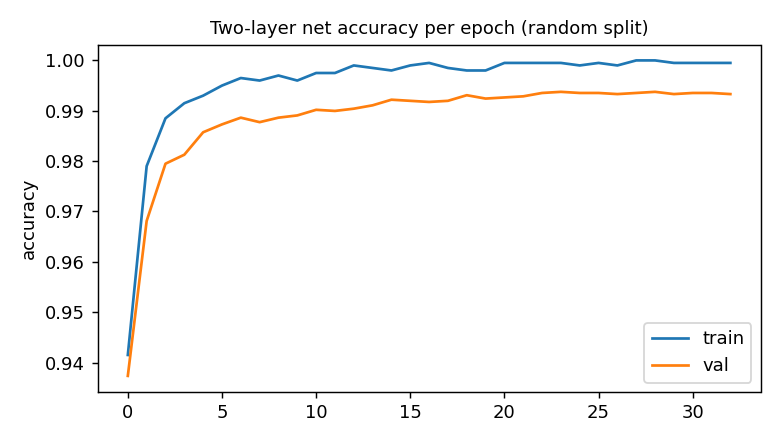

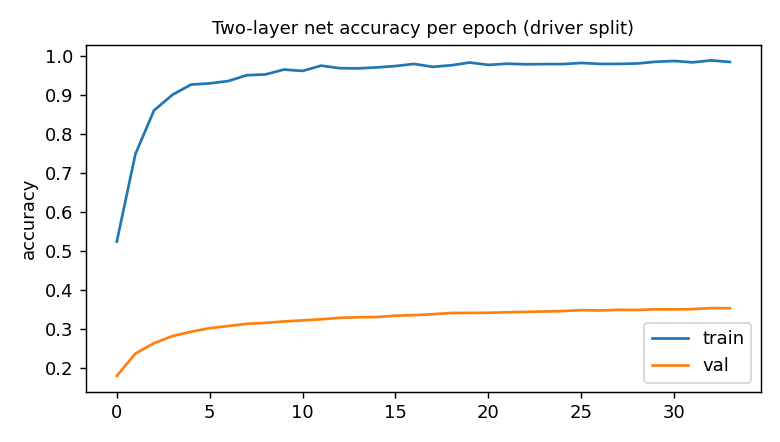

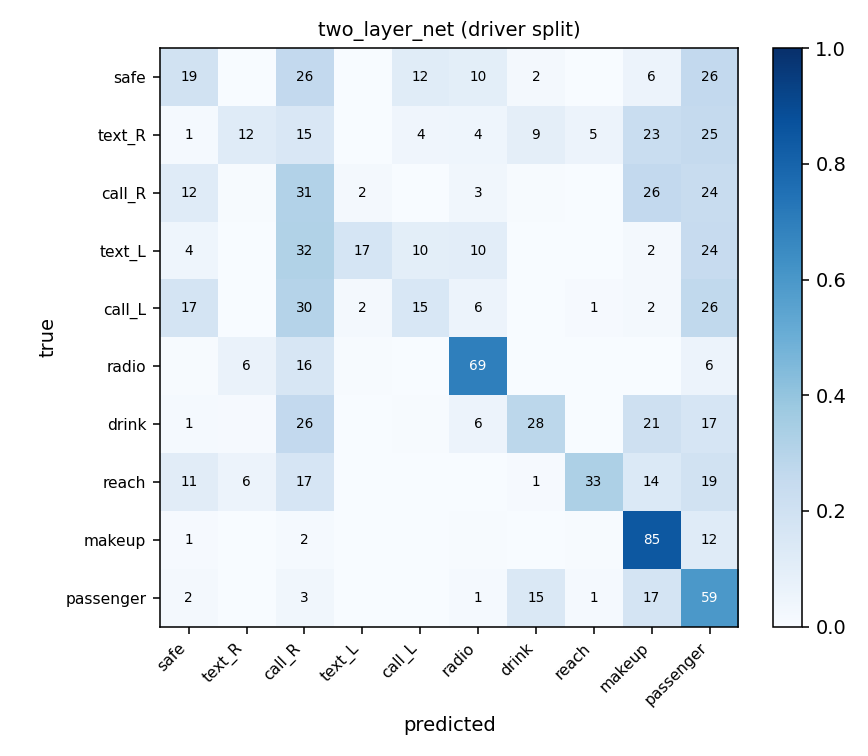

In [6]:
import json, glob
for f in sorted(glob.glob('/content/drive/MyDrive/DDD_Team7/outputs/results/*.json')):
    r = json.load(open(f))
    if r.get('model') in ('linear_svm', 'softmax', 'two_layer_net'):
        print(f"{r['model']:15s} {r['split']:7s} train {100*r['train_acc']:.1f}%  val {100*r['val_acc']:.1f}%  best {r['hyperparameters']}")
for f in ['class_distribution', 'acc_two_layer_net_random', 'acc_two_layer_net_driver', 'cm_two_layer_net_driver']:
    display(Image('/content/drive/MyDrive/DDD_Team7/outputs/results/figures/' + f + '.png'))